MULTIPLE LINEAR REGRESSION
BILLING AMOUNT AS THE RESPONSE VARIABLE
Valid observations: 55392
Mean centered Age: 0.0
Mean centered Length of Stay: -0.0

MODEL 1: AGE ONLY
                            OLS Regression Results                            
Dep. Variable:          Billing_Clean   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.7813
Date:                Tue, 06 Oct 2026   Prob (F-statistic):              0.377
Time:                        16:16:39   Log-Likelihood:            -6.0812e+05
No. Observations:               55392   AIC:                         1.216e+06
Df Residuals:                   55390   BIC:                         1.216e+06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err      

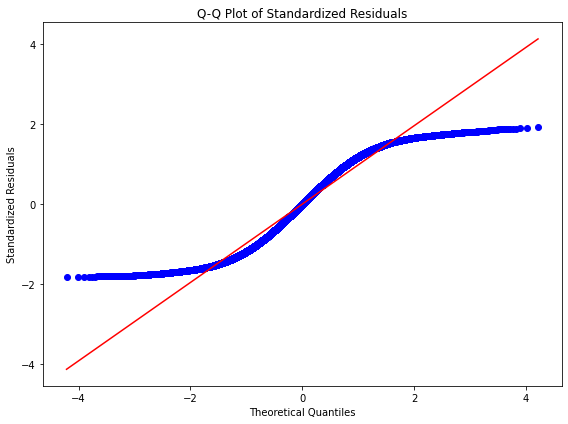

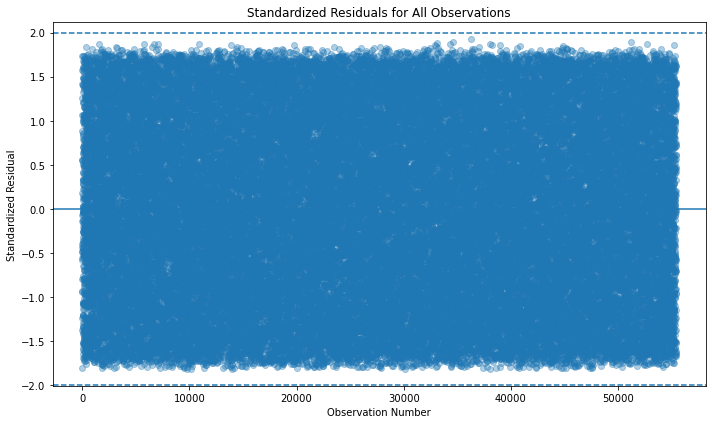

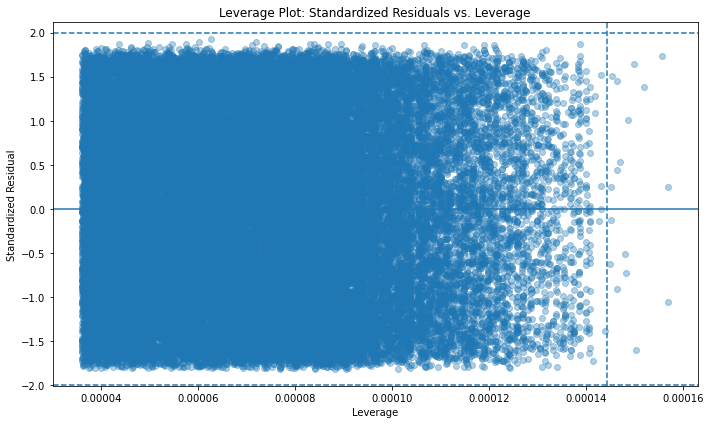


DIAGNOSTIC SUMMARY
Minimum standardized residual: -1.817
Maximum standardized residual: 1.928
Observations with |standardized residual| > 2: 0
Maximum leverage: 0.000157
Leverage cutoff: 0.000144
Maximum Cook's distance: 0.000121

ANALYSIS COMPLETE


In [1]:
# Project Title

#**Multiple Regression Analysis of Patient Age, Gender, Length of Stay, and Billing Amount**

## Multiple Regression Analysis

#For this assignment, I examined whether **patient Age** was associated with **Billing Amount** after adjusting for **Gender** and **Length of Stay**.

#The response variable was Billing Amount. My primary explanatory variable was Age. Gender and Length of Stay were added as additional explanatory variables to evaluate whether they confounded the relationship between Age and Billing Amount.

#Age and Length of Stay were centered around their means before running the regression model.

## Python Program

#```python
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import scipy.stats as stats
import glob
import os

# ============================================================
# FIND AND LOAD DATA
# ============================================================

csv_files = glob.glob("**/*.csv", recursive=True)

data_file = None

for file in csv_files:
    if os.path.basename(file).lower() == "healthcare_dataset.csv":
        data_file = file
        break

if data_file is None:
    for file in csv_files:
        if "healthcare" in os.path.basename(file).lower():
            data_file = file
            break

if data_file is None:
    raise FileNotFoundError(
        "healthcare_dataset.csv was not found. "
        "Please upload the healthcare dataset first."
    )

data = pd.read_csv(data_file, low_memory=False)

print("=" * 75)
print("MULTIPLE LINEAR REGRESSION")
print("BILLING AMOUNT AS THE RESPONSE VARIABLE")
print("=" * 75)

# ============================================================
# DATA MANAGEMENT
# ============================================================

# Age
data["Age_Clean"] = pd.to_numeric(
    data["Age"],
    errors="coerce"
)

data.loc[
    (data["Age_Clean"] < 0) |
    (data["Age_Clean"] > 120),
    "Age_Clean"
] = np.nan

# Billing Amount
data["Billing_Clean"] = pd.to_numeric(
    data["Billing Amount"],
    errors="coerce"
)

data.loc[
    data["Billing_Clean"] <= 0,
    "Billing_Clean"
] = np.nan

# Length of Stay
data["Admission_Date"] = pd.to_datetime(
    data["Date of Admission"],
    errors="coerce"
)

data["Discharge_Date"] = pd.to_datetime(
    data["Discharge Date"],
    errors="coerce"
)

data["Length_of_Stay"] = (
    data["Discharge_Date"] -
    data["Admission_Date"]
).dt.days

data.loc[
    (data["Length_of_Stay"] < 0) |
    (data["Length_of_Stay"] > 365),
    "Length_of_Stay"
] = np.nan

# Gender dummy variable:
# Male = 0
# Female = 1
data["Gender_Female"] = np.where(
    data["Gender"] == "Female",
    1,
    0
)

# Keep complete observations
regression_data = data[
    [
        "Billing_Clean",
        "Age_Clean",
        "Gender_Female",
        "Length_of_Stay"
    ]
].dropna().copy()

print(
    "Valid observations:",
    len(regression_data)
)

# ============================================================
# CENTER QUANTITATIVE VARIABLES
# ============================================================

regression_data["Age_Centered"] = (
    regression_data["Age_Clean"] -
    regression_data["Age_Clean"].mean()
)

regression_data["LOS_Centered"] = (
    regression_data["Length_of_Stay"] -
    regression_data["Length_of_Stay"].mean()
)

print(
    "Mean centered Age:",
    round(regression_data["Age_Centered"].mean(), 6)
)

print(
    "Mean centered Length of Stay:",
    round(regression_data["LOS_Centered"].mean(), 6)
)

# ============================================================
# MODEL 1: AGE ONLY
# ============================================================

X1 = sm.add_constant(
    regression_data[
        ["Age_Centered"]
    ]
)

model1 = sm.OLS(
    regression_data["Billing_Clean"],
    X1
).fit()

print("\n" + "=" * 75)
print("MODEL 1: AGE ONLY")
print("=" * 75)
print(model1.summary())

# ============================================================
# MODEL 2: AGE + GENDER
# ============================================================

X2 = sm.add_constant(
    regression_data[
        [
            "Age_Centered",
            "Gender_Female"
        ]
    ]
)

model2 = sm.OLS(
    regression_data["Billing_Clean"],
    X2
).fit()

print("\n" + "=" * 75)
print("MODEL 2: AGE + GENDER")
print("=" * 75)
print(model2.summary())

# ============================================================
# MODEL 3: FINAL MULTIPLE REGRESSION
# AGE + GENDER + LENGTH OF STAY
# ============================================================

X3 = sm.add_constant(
    regression_data[
        [
            "Age_Centered",
            "Gender_Female",
            "LOS_Centered"
        ]
    ]
)

model3 = sm.OLS(
    regression_data["Billing_Clean"],
    X3
).fit()

print("\n" + "=" * 75)
print("FINAL MULTIPLE REGRESSION MODEL")
print("=" * 75)
print(model3.summary())

# ============================================================
# CONFUNDING CHECK
# ============================================================

age_beta_model1 = model1.params["Age_Centered"]
age_beta_model2 = model2.params["Age_Centered"]
age_beta_model3 = model3.params["Age_Centered"]

gender_change = (
    abs(age_beta_model2 - age_beta_model1) /
    abs(age_beta_model1)
) * 100

final_change = (
    abs(age_beta_model3 - age_beta_model1) /
    abs(age_beta_model1)
) * 100

print("\n" + "=" * 75)
print("CONFOUNDING CHECK")
print("=" * 75)

print(
    "Age coefficient, Model 1:",
    round(age_beta_model1, 4)
)

print(
    "Age coefficient after adding Gender:",
    round(age_beta_model2, 4)
)

print(
    "Percent change after Gender:",
    round(gender_change, 2),
    "%"
)

print(
    "Age coefficient after adding Gender and Length of Stay:",
    round(age_beta_model3, 4)
)

print(
    "Percent change from Model 1 to final model:",
    round(final_change, 2),
    "%"
)

# ============================================================
# DIAGNOSTICS
# ============================================================

influence = model3.get_influence()

standardized_residuals = (
    influence.resid_studentized_internal
)

leverage = influence.hat_matrix_diag

cooks_distance = influence.cooks_distance[0]

# ------------------------------------------------------------
# Q-Q PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

stats.probplot(
    standardized_residuals,
    dist="norm",
    plot=plt
)

plt.title(
    "Q-Q Plot of Standardized Residuals"
)

plt.xlabel(
    "Theoretical Quantiles"
)

plt.ylabel(
    "Standardized Residuals"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STANDARDIZED RESIDUALS FOR ALL OBSERVATIONS
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    range(len(standardized_residuals)),
    standardized_residuals,
    alpha=0.35
)

plt.axhline(
    y=0,
    linestyle="-"
)

plt.axhline(
    y=2,
    linestyle="--"
)

plt.axhline(
    y=-2,
    linestyle="--"
)

plt.title(
    "Standardized Residuals for All Observations"
)

plt.xlabel(
    "Observation Number"
)

plt.ylabel(
    "Standardized Residual"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# LEVERAGE PLOT
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    leverage,
    standardized_residuals,
    alpha=0.35
)

plt.axhline(
    y=0,
    linestyle="-"
)

plt.axhline(
    y=2,
    linestyle="--"
)

plt.axhline(
    y=-2,
    linestyle="--"
)

leverage_cutoff = (
    2 * X3.shape[1] /
    len(regression_data)
)

plt.axvline(
    x=leverage_cutoff,
    linestyle="--"
)

plt.title(
    "Leverage Plot: Standardized Residuals vs. Leverage"
)

plt.xlabel(
    "Leverage"
)

plt.ylabel(
    "Standardized Residual"
)

plt.tight_layout()
plt.show()

# ============================================================
# DIAGNOSTIC SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("DIAGNOSTIC SUMMARY")
print("=" * 75)

print(
    "Minimum standardized residual:",
    round(standardized_residuals.min(), 3)
)

print(
    "Maximum standardized residual:",
    round(standardized_residuals.max(), 3)
)

print(
    "Observations with |standardized residual| > 2:",
    np.sum(np.abs(standardized_residuals) > 2)
)

print(
    "Maximum leverage:",
    round(leverage.max(), 6)
)

print(
    "Leverage cutoff:",
    round(leverage_cutoff, 6)
)

print(
    "Maximum Cook's distance:",
    round(cooks_distance.max(), 6)
)

print("\nANALYSIS COMPLETE")
#```

# Multiple Regression Output

#The final regression model included **55,392 valid observations**.

#| Explanatory Variable | Beta/B Coefficient | p-value |
#|---|---:|---:|
#| Centered Age | -2.68 | .384 |
#| Female Gender | -126.57 | .293 |
#| Centered Length of Stay | -9.09 | .191 |

#The intercept was approximately **$25,653.30**.

#The overall model was:

#**F(3, 55,388) = 1.194, p = .310**

#The model had an:

#**R² = 0.000065**

#This means that Age, Gender, and Length of Stay together explained only about **0.0065% of the variation in Billing Amount**.

# 1. Summary of Multiple Regression Results

#After adjusting for Gender and Length of Stay, **Age was not significantly associated with Billing Amount, B = -2.68, p = .384**.

#Holding Gender and Length of Stay constant, each additional year of age was associated with an estimated **$2.68 decrease in Billing Amount**. However, this relationship was not statistically significant.

#Gender was also not significantly associated with Billing Amount. Female patients had an estimated billing amount approximately **$126.57 lower than male patients, B = -126.57, p = .293**, after adjustment for Age and Length of Stay.

#Length of Stay was also not statistically significant. Each additional day of hospitalization was associated with an estimated **$9.09 decrease in Billing Amount, B = -9.09, p = .191**, holding Age and Gender constant.

#Overall, none of the three explanatory variables were statistically significant predictors of Billing Amount in this dataset.

# 2. Did the Results Support My Hypothesis?

#My primary hypothesis was that **patient Age would be associated with Billing Amount**.

#The final regression model did **not support this hypothesis**.

#After controlling for Gender and Length of Stay, the Age coefficient remained very small and statistically nonsignificant:

#**B = -2.68, p = .384**

#Therefore, there was insufficient evidence to conclude that patient Age predicts Billing Amount in this synthetic healthcare dataset.

# 3. Evidence of Confounding

#To investigate potential confounding, I added explanatory variables to the regression model one at a time.

#In the Age-only model:

#**Age B = -2.7166**

#After adding Gender:

#**Age B = -2.7097**

#This represents only about a **0.26% change** in the Age coefficient.

#After adding both Gender and Length of Stay:

#**Age B = -2.6761**

#This represents only about a **1.49% change** from the original Age-only coefficient.

#These changes are very small. A commonly used practical guideline is that a substantial change in the primary regression coefficient, often around 10% or more, may suggest confounding.

#Therefore, there was **no meaningful evidence that Gender or Length of Stay confounded the relationship between Age and Billing Amount**.

#The lack of confounding is also consistent with the fact that Age remained statistically nonsignificant in all of the models.

# 4. Regression Diagnostic Plots

## Q-Q Plot

#The Q-Q plot compares the distribution of the regression residuals with what would be expected under a normal distribution.

#The residuals were centered around zero, but the Q-Q plot showed some systematic departure from the theoretical normal line. This suggests that the residual distribution is **not perfectly normal**.

#Because the sample size is extremely large, minor departures from normality are easier to detect. However, the deviation should still be noted when interpreting the model.

## Standardized Residual Plot

#The standardized residuals ranged approximately from:

#**-1.82 to +1.93**

#There were **no observations with an absolute standardized residual greater than 2**.

#This suggests that the model does not contain obvious extreme residual outliers according to the commonly used ±2 criterion.

#However, the very low R² shows that the model itself explains almost none of the variability in Billing Amount. Therefore, even though extreme residual outliers are not apparent, the overall predictive fit of the model is very poor.

## Leverage Plot

#The average leverage was very small because of the large sample size.

#The maximum leverage was approximately:

#**0.000157**

#Using a leverage guideline of approximately:

#**2(k + 1) / n = 0.000144**

#a small number of observations were slightly above the screening threshold. However, the maximum leverage value remained extremely small.

#No observations exceeded the more conservative three-times-average leverage threshold.

#The maximum Cook's Distance was approximately:

#**0.000121**

#This is also extremely small, suggesting that there were **no highly influential individual observations that substantially changed the regression results**.

# Diagnostic Interpretation

#Taken together, the diagnostic plots suggest that the residual distribution is not perfectly normal, although no extreme standardized residual outliers were identified.

#The leverage analysis did not identify any observations with unusually large influence on the fitted regression model. Cook's Distance values were also extremely small.

#The more important issue is **poor model fit**. The final R² was approximately **0.000065**, meaning Age, Gender, and Length of Stay explain almost none of the variation in Billing Amount.

#Therefore, although there is little evidence that individual influential observations are driving the results, the selected explanatory variables are not useful predictors of Billing Amount in this synthetic dataset.

# Overall Conclusion

#The multiple regression analysis did not identify a statistically significant association between Billing Amount and any of the three explanatory variables.

#After adjustment for Gender and Length of Stay, Age remained nonsignificant:

#**Age: B = -2.68, p = .384**

#Gender was nonsignificant:

#**Female Gender: B = -126.57, p = .293**

#Length of Stay was also nonsignificant:

#**Length of Stay: B = -9.09, p = .191**

#My hypothesis that Age would be associated with Billing Amount was therefore **not supported**.

#There was also **no meaningful evidence of confounding**, because adding Gender and Length of Stay produced less than a 2% change in the Age regression coefficient.

#Finally, the regression diagnostics showed no major individual outliers or highly influential observations, but the model had extremely poor explanatory power. Additional patient, clinical, or healthcare-system characteristics would likely be needed to explain variation in Billing Amount.

## URL

#**Paste the URL of your published blog entry here.**